# Anime Review Sentiment — Notebook 3: Modelling & Evaluation

Trains and compares classifiers, benchmarks them against pre-trained transformers, scores the final model on
the held-out Dataset B, and turns the predictions into business insight.

**At a glance**
- **Final model: Linear SVM + TF-IDF — 94.4% accuracy, 0.914 macro-F1 on unseen Dataset B**
- Chosen from 3 models × 2 text representations by 5-fold cross-validated macro-F1
- **Matches zero-shot RoBERTa-large** (0.917 macro-F1) at ~25× the speed, with explainable weights
- Errors concentrate at 4 and 7 stars, right next to the dropped neutral band
- Business layer: a per-title health dashboard with an alert, plus aspect analysis — **pacing** draws the most criticism

| Input | Output |
|---|---|
| `data/Dataset_A_clean.csv`, `data/clean_artifacts.json` | `data/final_sentiment_model.joblib` |
| `data/Dataset_B_raw.csv` (first used in Section 9) | Final evaluation and business analysis |

**On transformers.** Fine-tuning one on ~16,000 long reviews would take hours on a CPU, so two pre-trained
transformers are used **zero-shot, as benchmarks**: DistilBERT (~66M parameters, tuned on movie reviews) and
RoBERTa-large (~355M, tuned on several sentiment datasets).

**Pipeline:** 1. Scraping → 2. Data Preparation → **3. Modelling & Evaluation**

## 1. Setup & load the cleaned training data

In [1]:

# Imports

import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, accuracy_score, roc_curve, auc,
                             precision_recall_curve, average_precision_score)
import joblib

DATA_DIR = "data"
RANDOM_STATE = 42
# Meta-feature names are read from notebook 2, so this
# notebook always uses exactly the features that survived screening there.
with open(os.path.join(DATA_DIR, "clean_artifacts.json"), encoding="utf-8") as _f:
    META_COLS = json.load(_f)["keep_meta"]
print("Meta-features carried over from notebook 2:", META_COLS)

df = pd.read_csv(os.path.join(DATA_DIR, "Dataset_A_clean.csv"))
df["clean_text"] = df["clean_text"].fillna("")
print(f"Loaded cleaned Dataset A: {df.shape[0]:,} rows")
print("Class balance:", df["sentiment"].value_counts(normalize=True).round(3).to_dict())
df[["sentiment", "clean_text"] + META_COLS].head(3)


Meta-features carried over from notebook 2: ['question_count', 'uppercase_word_count']
Loaded cleaned Dataset A: 16,021 rows
Class balance: {1: 0.804, 0: 0.196}


,sentiment,clean_text,question_count,uppercase_word_count
0,1,dear even begin talk friend couple everyone ta...,6.0,4.0
1,1,start follow quite frankly don see plot suck h...,2.0,3.0
2,1,mobile suit gundam catapult japan dragon ball ...,1.0,16.0


## 2. Train / validation split

Stratified 80/20 split of Dataset A. The **validation set** is used to choose and tune models, so after
tuning it is no longer a fully honest estimate. **Dataset B** plays no part in any decision, and is what the
final model is judged on.

In [2]:

# Step 1 — stratified 80/20 train/validation split

X = df[["clean_text"] + META_COLS].copy()
y = df["sentiment"].values

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,}   Validation: {len(X_val):,}")
print(f"Train positive rate: {y_train.mean():.3f} | Val positive rate: {y_val.mean():.3f}")


Train: 12,816   Validation: 3,205
Train positive rate: 0.804 | Val positive rate: 0.804


## 3. Text representation: Bag-of-Words vs TF-IDF

| | Produces | Expected to suit |
|---|---|---|
| **Bag-of-Words** | Raw word counts | Naive Bayes, which models word counts |
| **TF-IDF** | Counts down-weighted for words common to every review | Linear models (Logistic Regression, SVM) |

Shared settings: **unigrams + bigrams**, so *"not good"* becomes a feature (the reason negations were kept in
notebook 2); `min_df=5` to ignore typos; `max_features=20000`. The two style features are scaled with
`MaxAbsScaler`, which keeps them non-negative as Naive Bayes requires.

In [3]:

# Step 2 — feature builder: pick BoW or TF-IDF + optional meta-features

def build_features(vectorizer="tfidf", use_meta=True, **vec_kw):
    """ColumnTransformer combining a text vectoriser ('tfidf' or 'count'=BoW)
    with the optional scaled meta-features. Transformer is named 'vec' either
    way, so downstream param names stay stable regardless of vectoriser."""
    common = dict(ngram_range=(1, 2), min_df=5, max_features=20000)
    common.update(vec_kw)
    if vectorizer == "tfidf":
        vec = TfidfVectorizer(sublinear_tf=True, **common)
    elif vectorizer == "count":                       # Bag-of-Words: raw term counts
        vec = CountVectorizer(**common)
    else:
        raise ValueError(f"unknown vectorizer: {vectorizer}")
    transformers = [("vec", vec, "clean_text")]
    if use_meta:
        transformers.append(("meta", MaxAbsScaler(), META_COLS))
    return ColumnTransformer(transformers, sparse_threshold=0.3)

# both vectorisers share the same vocabulary size. only the values differ
_Xt = build_features("tfidf", use_meta=True).fit_transform(X_train, y_train)
print(f"Feature matrix: {_Xt.shape[0]:,} docs x {_Xt.shape[1]:,} features")
print(f"Sparsity: {100*(1 - _Xt.nnz/(_Xt.shape[0]*_Xt.shape[1])):.2f}% zeros")


Feature matrix: 12,816 docs x 20,002 features
Sparsity: 98.90% zeros


## 4. Model comparison — 3 models × 2 representations

Naive Bayes, Logistic Regression and Linear SVM, each with BoW and TF-IDF, scored by 5-fold stratified
cross-validation and on the validation set. The linear models use `class_weight="balanced"`.

**Ranking metric: macro-F1**, the unweighted average of each class's F1. With 80% positive data, a model that
always says "positive" gets ~80% accuracy but a poor macro-F1, so macro-F1 shows whether the negative class
is really being learned.

In [4]:

# Step 3 — evaluate 3 models x 2 vectorisers (CV + validation)

models = {
    "Naive Bayes": MultinomialNB(),
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "LinearSVM":  LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
}
VECTORIZERS = {"BoW": "count", "TF-IDF": "tfidf"}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for vlabel, vkey in VECTORIZERS.items():
    for name, clf in models.items():
        pipe = Pipeline([("features", build_features(vectorizer=vkey, use_meta=True)), ("clf", clone(clf))])
        cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_val)
        rows.append({
            "Model": name, "Vectorizer": vlabel,
            "CV macro-F1": round(float(cv_f1.mean()), 4),
            "Val macro-F1": round(f1_score(y_val, pred, average="macro"), 4),
            "Val F1 (neg)": round(f1_score(y_val, pred, pos_label=0), 4),
            "Val F1 (pos)": round(f1_score(y_val, pred, pos_label=1), 4),
            "Val accuracy": round(accuracy_score(y_val, pred), 4),
        })
results = pd.DataFrame(rows)
results.sort_values("CV macro-F1", ascending=False).reset_index(drop=True)


,Model,Vectorizer,CV macro-F1,Val macro-F1,Val F1 (neg),Val F1 (pos),Val accuracy
0,LinearSVM,TF-IDF,0.8989,0.8996,0.8389,0.9603,0.9363
1,LogisticRegression,TF-IDF,0.8962,0.8972,0.8369,0.9575,0.9326
2,LogisticRegression,BoW,0.8871,0.8894,0.8220,0.9568,0.9304
3,LinearSVM,BoW,0.8755,0.8713,0.7915,0.9511,0.9207
4,Naive Bayes,BoW,0.8720,0.8768,0.8061,0.9475,0.9173
5,Naive Bayes,TF-IDF,0.6150,0.6757,0.4328,0.9187,0.8577


CV macro-F1 by model x vectoriser:
Vectorizer             BoW  TF-IDF
Model                             
LinearSVM           0.8755  0.8989
LogisticRegression  0.8871  0.8962
Naive Bayes         0.8720  0.6150 



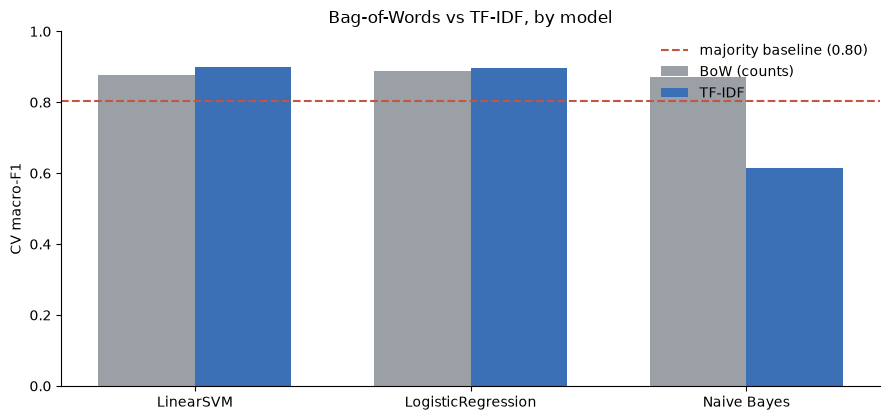

In [5]:

# Step 3b — BoW vs TF-IDF, grouped by model (macro-F1)

pivot = results.pivot(index="Model", columns="Vectorizer", values="CV macro-F1")
print("CV macro-F1 by model x vectoriser:")
print(pivot.round(4), "\n")

fig, ax = plt.subplots(figsize=(9, 4.3))
x = np.arange(len(pivot)); w = 0.35
ax.bar(x - w/2, pivot["BoW"],    w, label="BoW (counts)",  color="#9AA0A6")
ax.bar(x + w/2, pivot["TF-IDF"], w, label="TF-IDF",        color="#3B6FB6")
ax.axhline(max(y_val.mean(), 1-y_val.mean()), ls="--", color="#C4553E",
           label=f"majority baseline ({max(y_val.mean(),1-y_val.mean()):.2f})")
ax.set_xticks(x); ax.set_xticklabels(pivot.index); ax.set_ylabel("CV macro-F1"); ax.set_ylim(0, 1)
ax.set_title("Bag-of-Words vs TF-IDF, by model")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()


In [6]:

# Step 3c — pick the single best (model, vectoriser) combo

best_row  = results.loc[results["CV macro-F1"].idxmax()]
best_name = best_row["Model"]
best_vec  = VECTORIZERS[best_row["Vectorizer"]]
print(f"Best combo: {best_name} + {best_row['Vectorizer']} "
      f"(CV macro-F1 = {best_row['CV macro-F1']})")

# Showing if BOW is better for Naive bayes
nb = results[results.Model == "Naive Bayes"].set_index("Vectorizer")["CV macro-F1"]
print(f"\nNaive Bayes:  BoW = {nb['BoW']:.4f}  vs  TF-IDF = {nb['TF-IDF']:.4f}  "
      f"-> BoW is {'BETTER' if nb['BoW'] > nb['TF-IDF'] else 'not better'} for NB")


Best combo: LinearSVM + TF-IDF (CV macro-F1 = 0.8989)

Naive Bayes:  BoW = 0.8720  vs  TF-IDF = 0.6150  -> BoW is BETTER for NB


**Insight — the best representation depends on the model.**
- **Naive Bayes needs BoW:** 0.872 vs 0.615 on TF-IDF, with negative-class F1 falling from 0.81 to 0.43. It
  assumes independent word counts, and TF-IDF values are corpus-dependent weights rather than counts.
- **The linear models prefer TF-IDF:** they make no independence assumption and benefit from common words
  being down-weighted.
- Every combination clears the majority baseline. **Linear SVM + TF-IDF** (CV macro-F1 0.8989) goes forward.

## 5. Do the style features help?

Each model is trained on text only, then on text + the two style features from notebook 2. Building a
feature doesn't prove it helps.

In [7]:

# Step 4 — ablation: text-only vs text+meta

# run the features using each model's own best vectoriser choice
best_vec_per_model = (results.loc[results.groupby("Model")["CV macro-F1"].idxmax()]
                      .set_index("Model")["Vectorizer"].map(VECTORIZERS).to_dict())

abl = []
for name, clf in models.items():
    vkey = best_vec_per_model[name]
    for use_meta in (False, True):
        pipe = Pipeline([("features", build_features(vectorizer=vkey, use_meta=use_meta)),
                         ("clf", clone(clf))])
        f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
        abl.append({"Model": name, "Features": "text+meta" if use_meta else "text only",
                    "CV macro-F1": round(float(f1), 4)})
ablation = pd.DataFrame(abl).pivot(index="Model", columns="Features", values="CV macro-F1")
ablation["delta"] = (ablation["text+meta"] - ablation["text only"]).round(4)
ablation


Features,text only,text+meta,delta
Model,,,
LinearSVM,0.8981,0.8989,0.0008
LogisticRegression,0.8969,0.8962,-0.0007
Naive Bayes,0.8721,0.8720,-0.0001


**Insight — no measurable effect.** The changes are +0.0008 (SVM), −0.0007 (LogReg) and −0.0001 (NB), all
within cross-validation noise. The features are kept because the chosen SVM is the one model with a positive
delta and they are cheap to compute — a marginal call, reported as one. The real finding: **TF-IDF already
captures almost all the signal**. *How* a review is written adds almost nothing to *which words* it uses.

## 6. Hyperparameter tuning

`GridSearchCV` (5-fold, macro-F1) searches the vectoriser settings and the SVM's `C` together, since the best
`C` depends on how many features the vectoriser produces.

**Result: no change.** The best parameters were the defaults (`C=1.0`, bigrams, `min_df=5`) with the same
0.8989 score. Performance is driven by the **features** — the cleaning and name removal in notebook 2 — not
by hyperparameters.

In [8]:

# Step 5 — grid search on the best (model, vectoriser) combo

print(f"Tuning best combo from Section 4: {best_name} + {best_row['Vectorizer']}")

pipe = Pipeline([("features", build_features(vectorizer=best_vec, use_meta=True)),
                 ("clf", clone(models[best_name]))])

# transformer is named 'vec' regardless of BoW/TF-IDF, so these param names are stable
param_grid = {
    "features__vec__ngram_range": [(1, 1), (1, 2)],
    "features__vec__min_df": [3, 5],
}
if best_name == "Naive Bayes":
    param_grid["clf__alpha"] = [0.1, 0.5, 1.0]
else:
    param_grid["clf__C"] = [0.1, 1.0, 10.0]

grid = GridSearchCV(pipe, param_grid, scoring="f1_macro", cv=cv, n_jobs=-1, verbose=1)
t0 = time.time()
grid.fit(X_train, y_train)
print(f"\nGrid search done in {time.time()-t0:.0f}s")
print("Best params:", grid.best_params_)
print(f"Best CV macro-F1: {grid.best_score_:.4f}")

best_model = grid.best_estimator_


Tuning best combo from Section 4: LinearSVM + TF-IDF
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Grid search done in 35s
Best params: {'clf__C': 1.0, 'features__vec__min_df': 5, 'features__vec__ngram_range': (1, 2)}
Best CV macro-F1: 0.8989


## 7. Detailed evaluation (validation set)

A classification report and confusion matrix, then ROC and precision-recall curves. The report describes a
single decision threshold; the curves cover every threshold. The precision-recall curve matters most here: it
focuses on the minority class, and it is what you would use to set the "send to a human" threshold
recommended in Section 10.

              precision    recall  f1-score   support

Negative (0)       0.83      0.84      0.84       629
Positive (1)       0.96      0.96      0.96      2576

    accuracy                           0.94      3205
   macro avg       0.90      0.90      0.90      3205
weighted avg       0.94      0.94      0.94      3205



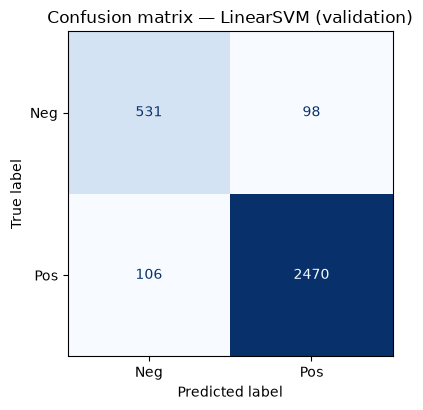

In [9]:

# Step 6a — classification report + confusion matrix

val_pred = best_model.predict(X_val)
print(classification_report(y_val, val_pred, target_names=["Negative (0)", "Positive (1)"]))

fig, ax = plt.subplots(figsize=(4.8, 4.2))
cm = confusion_matrix(y_val, val_pred)
ConfusionMatrixDisplay(cm, display_labels=["Neg", "Pos"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix — {best_name} (validation)")
plt.tight_layout(); plt.show()


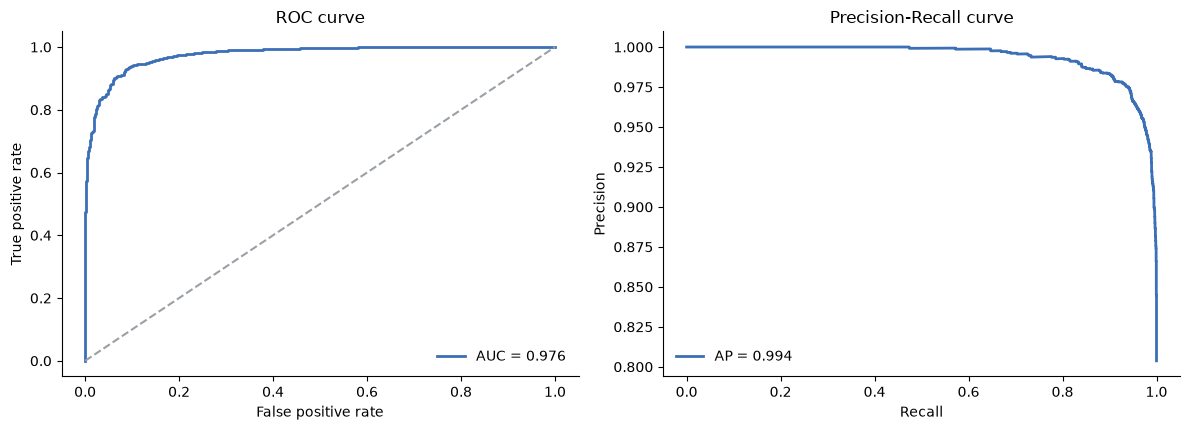

In [10]:
# ============================================================
# Step 6b — ROC & precision-recall curves
# ============================================================
def get_scores(model, X):
    """Positive-class score, whether the model exposes probabilities or margins."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

val_scores = get_scores(best_model, X_val)
fpr, tpr, _ = roc_curve(y_val, val_scores)
prec, rec, _ = precision_recall_curve(y_val, val_scores)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].plot(fpr, tpr, color="#3B6FB6", lw=2, label=f"AUC = {auc(fpr, tpr):.3f}")
axes[0].plot([0, 1], [0, 1], ls="--", color="#9AA0A6")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve"); axes[0].legend(frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].plot(rec, prec, color="#3B6FB6", lw=2,
             label=f"AP = {average_precision_score(y_val, val_scores):.3f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve"); axes[1].legend(frameon=False)
axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()


In [11]:

# Step 6c — most informative words (model interpretability)

clf = best_model.named_steps["clf"]
feat_names = best_model.named_steps["features"].get_feature_names_out()
# strip the transformer prefixes ("tfidf__", "meta__") for readability
feat_names = [f.split("__", 1)[-1] for f in feat_names]

if hasattr(clf, "coef_"):
    coefs = clf.coef_[0]
    order = np.argsort(coefs)
    top_neg = [(feat_names[i], round(coefs[i], 3)) for i in order[:15]]
    top_pos = [(feat_names[i], round(coefs[i], 3)) for i in order[-15:][::-1]]
    interp = pd.DataFrame({
        "Top POSITIVE words": [w for w, _ in top_pos],
        "weight (+)":         [c for _, c in top_pos],
        "Top NEGATIVE words": [w for w, _ in top_neg],
        "weight (-)":         [c for _, c in top_neg],
    })
    display(interp)
else:
    print("Selected model does not expose linear coefficients.")


,Top POSITIVE words,weight (+),Top NEGATIVE words,weight (-)
0,fun,2.395,bad,-3.607
1,great,2.313,nothing,-2.707
2,definitely,2.136,pathetic,-2.430
3,well,2.020,poorly,-2.296
4,amaze,1.907,boring,-2.249
5,lot,1.893,waste,-2.244
6,amazing,1.756,suppose,-2.218
7,although,1.741,crap,-2.035
8,awesome,1.720,mess,-2.008
9,complain,1.712,disappointment,-2.006


### Insight — the model learned sentiment, not names

| Strongest positive weights | Strongest negative weights |
|---|---|
| great, fun, definitely, amaze, awesome, amazing, enjoyable, hilarious, perfect | bad, nothing, pathetic, poorly, boring, waste, crap, mess, garbage, ruin |

**No character, show or studio name appears** — direct evidence that notebook 2's name removal worked. Three
subtler weights stand out:

| Feature | Weight | Why it makes sense |
|---|---|---|
| `not recommend` | −1.85 | A bigram — only possible because negations were kept *and* bigrams were enabled |
| `decent` | −1.88 | Faint praise: "decent" usually comes with a low rating. A hand-written keyword list would get this wrong |
| `complain` | +1.62 | Almost certainly from "nothing to complain about" |

### Error analysis — where does it go wrong?

Errors by direction, by original star rating, and the most *confident* mistakes (largest margin in the wrong
direction).

In [12]:

# Step 6d - error analysis on the validation set

errors = pd.DataFrame({
    "rating": df.loc[X_val.index, "rating"].values,
    "true":   y_val,
    "pred":   val_pred,
    "margin": val_scores,          # signed distance from the decision boundary
    "text":   df.loc[X_val.index, "review_text"].values,
})
errors["correct"] = errors["true"] == errors["pred"]
wrong = errors[~errors["correct"]]

n_fp = int(((errors["true"] == 0) & (errors["pred"] == 1)).sum())   # said positive, was negative
n_fn = int(((errors["true"] == 1) & (errors["pred"] == 0)).sum())   # said negative, was positive
print(f"Misclassified: {len(wrong):,} of {len(errors):,} ({len(wrong)/len(errors)*100:.1f}%)")
print(f"  False positives (predicted positive, actually negative): {n_fp}")
print(f"  False negatives (predicted negative, actually positive): {n_fn}")

# ---- where do the errors sit on the original 1-10 star scale? 
by_rating = (errors.groupby("rating")
                   .agg(reviews=("correct", "size"), wrong=("correct", lambda s: (~s).sum()))
                   .assign(error_rate_pct=lambda d: (d["wrong"] / d["reviews"] * 100).round(1)))
print("\nError rate by original star rating:")
display(by_rating)

# ---- the most confident mistakes in each direction 
def show(subset, title):
    print(f"\n{title}")
    if subset.empty:
        print("  (none)")
        return
    for _, r in subset.iterrows():
        txt = " ".join(str(r["text"]).split())[:230]
        print(f"  [{int(r['rating'])} stars | margin {r['margin']:+.2f}] {txt}...")

show(wrong[wrong["true"] == 0].nlargest(3, "margin"),
     "MOST CONFIDENT FALSE POSITIVES (model said positive, reviewer rated 1-4):")
show(wrong[wrong["true"] == 1].nsmallest(3, "margin"),
     "MOST CONFIDENT FALSE NEGATIVES (model said negative, reviewer rated 7-10):")


Misclassified: 204 of 3,205 (6.4%)
  False positives (predicted positive, actually negative): 98
  False negatives (predicted negative, actually positive): 106

Error rate by original star rating:


,reviews,wrong,error_rate_pct
rating,,,
1,120,14,11.7
2,107,11,10.3
3,198,27,13.6
4,204,46,22.5
7,348,53,15.2
8,554,21,3.8
9,766,17,2.2
10,908,15,1.7



MOST CONFIDENT FALSE POSITIVES (model said positive, reviewer rated 1-4):
  [4 stars | margin +1.20] Monster is touted as a masterpiece of the psychological thriller genre, boasting some of the greatest characters you'll find in an anime, and a story that is close to unrivaled in the medium. I think of Death Note as quite possibl...
  [1 stars | margin +1.06] "Kanojo, Okarishimasu" is a one-of-a-kind masterpiece! It's been a long time since something was released that could truly be considered a great anime or that was enjoyable to watch from start to finish. Originally written and ill...
  [1 stars | margin +0.93] Opening Banger. Anime, ass. Please don't be like my guy who read the manga. Get bitches, and touch grass. Steins;Gates is a must-watch series, if only to watch how it consistently pushes boundaries in the genre of science fiction....

MOST CONFIDENT FALSE NEGATIVES (model said negative, reviewer rated 7-10):
  [7 stars | margin -1.22] Decided to make my first review on this

**Insight — the model fails where the label itself is weakest.** Error rates peak at **4 stars (22.5%)** and
**7 stars (15.2%)**, the ratings right next to the dropped 5–6 band, and fall steadily to 1.7% at 10 stars.
Errors are close to symmetric (98 false positives vs 106 false negatives), so class weighting did its job.

**The confident mistakes are about context, not vocabulary:**
- Praise aimed at a *different* show — a 4-star *Death Note* review that opens by calling *Monster* "a masterpiece".
- Irony or jokes — "a one-of-a-kind masterpiece" in a 1-star review.
- Positive reviews arguing *against* other people's negative opinions.

More data would not fix these. A bag-of-words model cannot tell what sentiment is directed at, which is
exactly where a transformer's attention mechanism helps.

### Transformer predictions are cached

Transformer inference takes ~12 of this notebook's ~20 minutes. It is deterministic, so results are cached in
`data/transformer_cache/`, keyed on a hash of the model name **and the exact review texts**: if the data
changes at all, the cache misses and inference re-runs. Each cell prints whether it hit the cache.

In [13]:

# Transformer prediction cache

import hashlib
from transformers import pipeline as hf_pipeline

TF_CACHE = os.path.join(DATA_DIR, "transformer_cache")
os.makedirs(TF_CACHE, exist_ok=True)

def cached_sentiment(model_name, texts, batch_size=16):
    """Return POSITIVE/NEGATIVE labels for `texts`, caching by (model, exact texts).

    Inference is deterministic, so a cache hit is equivalent to re-running. The key
    includes a hash of the texts themselves, so changed data invalidates the cache
    instead of returning predictions that no longer match."""
    key = hashlib.md5(("|".join([model_name] + list(texts))).encode("utf-8")).hexdigest()
    path = os.path.join(TF_CACHE, f"{key}.json")
    short = model_name.split("/")[-1]

    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            payload = json.load(f)
        if len(payload["labels"]) == len(texts):
            print(f"  [cache HIT ] {short}: {len(texts):,} reviews loaded from disk")
            return payload["labels"]

    print(f"  [cache MISS] {short}: running inference on {len(texts):,} reviews ...")
    clf = hf_pipeline("sentiment-analysis", model=model_name,
                      truncation=True, max_length=512, device=-1)
    t0 = time.time()
    out = clf(list(texts), batch_size=batch_size)
    labels = [o["label"] for o in out]
    elapsed = time.time() - t0
    print(f"  [done      ] {short}: {elapsed:.0f}s "
          f"({elapsed/max(len(texts),1)*1000:.0f} ms per review)")
    with open(path, "w", encoding="utf-8") as f:
        json.dump({"model": model_name, "n": len(texts), "labels": labels}, f)
    return labels

DISTILBERT = "distilbert-base-uncased-finetuned-sst-2-english"
ROBERTA    = "siebert/sentiment-roberta-large-english"
print(f"cache directory: {TF_CACHE}")
print(f"cached results already present: {len(os.listdir(TF_CACHE))}")


cache directory: data\transformer_cache
cached results already present: 3


## 8. Benchmark 1 — DistilBERT (zero-shot)

Is a simple domain-trained model good enough, or does a pre-trained deep model do much better? Transformers
read word order and context, but cost far more to run. Both transformers receive the **raw** review text,
because their tokenisers expect natural language and the aggressive cleaning would handicap them.

In [14]:

# Step 7 — DistilBERT benchmark on the validation set

# align raw text with the validation rows (via original index)
val_raw = df.loc[X_val.index, "review_text"].fillna("").astype(str).tolist()

labels = cached_sentiment(DISTILBERT, val_raw, batch_size=16)
bert_pred = np.array([1 if l == "POSITIVE" else 0 for l in labels])

print("\nDistilBERT (zero-shot) on validation set:")
print(classification_report(y_val, bert_pred, target_names=["Negative (0)", "Positive (1)"]))


  [cache HIT ] distilbert-base-uncased-finetuned-sst-2-english: 3,205 reviews loaded from disk

DistilBERT (zero-shot) on validation set:
              precision    recall  f1-score   support

Negative (0)       0.56      0.94      0.70       629
Positive (1)       0.98      0.82      0.89      2576

    accuracy                           0.84      3205
   macro avg       0.77      0.88      0.80      3205
weighted avg       0.90      0.84      0.85      3205



In [15]:

# Step 7b — head-to-head: our tuned model vs DistilBERT

def _scores(y_true, pred):
    return {"Accuracy": round(accuracy_score(y_true, pred), 4),
            "Macro-F1": round(f1_score(y_true, pred, average="macro"), 4),
            "F1 (neg)": round(f1_score(y_true, pred, pos_label=0), 4),
            "F1 (pos)": round(f1_score(y_true, pred, pos_label=1), 4)}

compare = pd.DataFrame({
    f"{best_name} (tuned)":    _scores(y_val, val_pred),
    "DistilBERT (zero-shot)":  _scores(y_val, bert_pred),
})
compare


,LinearSVM (tuned),DistilBERT (zero-shot)
Accuracy,0.9363,0.8415
Macro-F1,0.8996,0.7962
F1 (neg),0.8389,0.7001
F1 (pos),0.9603,0.8923


**Insight — DistilBERT loses clearly** (macro-F1 0.796 vs 0.900). It was fine-tuned on movie reviews and
knows nothing about how anime reviewers write or about this corpus's 4 : 1 prior. It is heavily biased towards
"negative" — negative recall 0.94 but precision only 0.56 — so it would raise many false alarms about titles
audiences actually liked. Section 9b checks whether a much larger transformer changes the picture.

## 9. Final test — Dataset B

**Refit on all of Dataset A first.** The validation split existed to make decisions; once they are locked,
holding it out just wastes ~25% of the training data, which matters most for the scarce negative class.
Dataset B played no part in any decision, so the test stays honest.

**Clean Dataset B with the frozen artifacts.** The model's features are a fixed vocabulary learned from A.
Re-deriving the stop-words or name list from B's 843 reviews would produce different lists and silently
change what each feature means (*train/serve skew*).

In [16]:

# Step 8a — rebuild the frozen cleaning pipeline for Dataset B

import re, string as _string
import nltk
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk import pos_tag
for _pkg in ["punkt", "punkt_tab", "wordnet", "omw-1.4",
             "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(_pkg, quiet=True)

artifacts = json.load(open(os.path.join(DATA_DIR, "clean_artifacts.json"), encoding="utf-8"))
STOPWORDS = set(artifacts["stopwords"])
STRIP_SET = set(artifacts["strip_set"])
print(f"Loaded frozen artifacts: {len(STOPWORDS)} stop-words, {len(STRIP_SET)} strip tokens")

lemmatizer = WordNetLemmatizer()
HTML_TAG_RE, HTML_ENT_RE = re.compile(r"<[^>]+>"), re.compile(r"&[a-z]+;")
URL_RE, REPEAT_PUNC = re.compile(r"http\S+|www\.\S+"), re.compile(r"([!?.])\1+")
NON_ALPHA_RE, MULTISPACE = re.compile(r"[^a-z\s]"), re.compile(r"\s+")

def _wn_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

def clean_text(text):
    """Identical core pipeline to notebook 2 + the frozen entity strip-set."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    for rgx in (HTML_TAG_RE, HTML_ENT_RE, URL_RE):
        text = rgx.sub(" ", text)
    text = REPEAT_PUNC.sub(r"\1", text)
    text = MULTISPACE.sub(" ", NON_ALPHA_RE.sub(" ", text)).strip()
    out = []
    for tok, tag in pos_tag(word_tokenize(text)):
        if len(tok) <= 2 or tok in STOPWORDS:
            continue
        lemma = lemmatizer.lemmatize(tok, _wn_pos(tag))
        if len(lemma) <= 2 or lemma in STOPWORDS or lemma in STRIP_SET:
            continue
        out.append(lemma)
    return " ".join(out)

def meta_features(text):
    """Compute the candidate stylistic features, then return only the ones that
    survived screening in notebook 2 (names come from clean_artifacts.json)."""
    if not isinstance(text, str) or not text:
        return pd.Series({c: 0 for c in META_COLS})
    words = text.split()
    candidates = {
        "exclamation_count":    text.count("!"),
        "question_count":       text.count("?"),
        "uppercase_word_count": sum(1 for w in words if len(w) >= 3 and w.isupper()),
    }
    return pd.Series({c: candidates.get(c, 0) for c in META_COLS})


Loaded frozen artifacts: 202 stop-words, 2427 strip tokens


In [17]:

# Step 8b — clean Dataset B with the frozen pipeline

dfB = pd.read_csv(os.path.join(DATA_DIR, "Dataset_B_raw.csv"))
print(f"Raw Dataset B: {len(dfB):,} rows")

# apply the SAME row-level cleaning as notebook 2, in the same order:
# (1a) de-duplicate on (anime_id, review_text)
_before = len(dfB)
dfB = dfB.drop_duplicates(subset=["anime_id", "review_text"]).reset_index(drop=True)
print(f"Duplicates removed: {_before - len(dfB)}")

# (1b) derive the same label + drop the same neutral band
dfB["sentiment"] = dfB["rating"].apply(lambda r: 1 if r >= 7 else (0 if r <= 4 else np.nan))
dfB = dfB.dropna(subset=["sentiment"]).copy()
dfB["sentiment"] = dfB["sentiment"].astype(int)

t0 = time.time()
dfB["clean_text"] = dfB["review_text"].apply(clean_text)
dfB = pd.concat([dfB, dfB["review_text"].apply(meta_features)], axis=1)
dfB = dfB[dfB["clean_text"].str.split().str.len() >= 3].reset_index(drop=True)
print(f"Dataset B cleaned in {time.time()-t0:.0f}s -> {len(dfB):,} test reviews")
print("Dataset B class balance:", dfB["sentiment"].value_counts(normalize=True).round(3).to_dict())


Raw Dataset B: 985 rows
Duplicates removed: 0
Dataset B cleaned in 16s -> 843 test reviews
Dataset B class balance: {1: 0.804, 0: 0.196}


In [18]:

# Step 8c — refit tuned model on ALL of Dataset A, predict Dataset B

best_params = grid.best_params_
final_model = Pipeline([("features", build_features(vectorizer=best_vec, use_meta=True)),
                        ("clf", clone(models[best_name]))])
final_model.set_params(**best_params)
final_model.fit(X, y)   # X, y = the FULL Dataset A

XB = dfB[["clean_text"] + META_COLS]
yB = dfB["sentiment"].values
B_pred = final_model.predict(XB)

print("=== FINAL held-out performance on Dataset B ===\n")
print(classification_report(yB, B_pred, target_names=["Negative (0)", "Positive (1)"]))
print(f"Accuracy : {accuracy_score(yB, B_pred):.4f}")
print(f"Macro-F1 : {f1_score(yB, B_pred, average='macro'):.4f}")


=== FINAL held-out performance on Dataset B ===

              precision    recall  f1-score   support

Negative (0)       0.84      0.89      0.86       165
Positive (1)       0.97      0.96      0.97       678

    accuracy                           0.94       843
   macro avg       0.90      0.92      0.91       843
weighted avg       0.95      0.94      0.94       843

Accuracy : 0.9442
Macro-F1 : 0.9136


  [cache HIT ] distilbert-base-uncased-finetuned-sst-2-english: 843 reviews loaded from disk


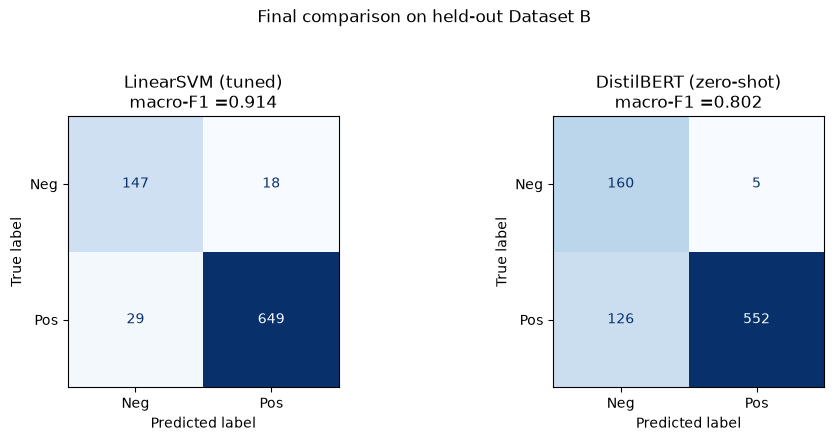

,LinearSVM (tuned),DistilBERT (zero-shot)
Accuracy,0.9442,0.8446
Macro-F1,0.9136,0.8017
F1 (neg),0.8622,0.7095
F1 (pos),0.9651,0.8939


In [19]:
# ============================================================
# Step 8d — Dataset B confusion matrix + classical vs DistilBERT on B
# ============================================================
# DistilBERT on the SAME Dataset B (raw text) for a final head-to-head
_B_text = dfB["review_text"].fillna("").astype(str).tolist()
B_bert_pred = np.array([1 if l == "POSITIVE" else 0
                        for l in cached_sentiment(DISTILBERT, _B_text, batch_size=16)])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, pred, title in [(axes[0], B_pred, f"{best_name} (tuned)"),
                        (axes[1], B_bert_pred, "DistilBERT (zero-shot)")]:
    ConfusionMatrixDisplay(confusion_matrix(yB, pred), display_labels=["Neg", "Pos"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{title}\nmacro-F1 ={f1_score(yB, pred, average='macro'):.3f}")
plt.suptitle("Final comparison on held-out Dataset B", y=1.04)
plt.tight_layout(); plt.show()

final_table = pd.DataFrame({
    f"{best_name} (tuned)":    _scores(yB, B_pred),
    "DistilBERT (zero-shot)":  _scores(yB, B_bert_pred),
})
final_table


## 9b. Benchmark 2 — RoBERTa-large (zero-shot)

Beating a small model invites the objection that the baseline was weak, so a much larger one is tested.

| | DistilBERT | RoBERTa-large |
|---|---|---|
| Checkpoint | `distilbert-base-uncased-finetuned-sst-2-english` | `siebert/sentiment-roberta-large-english` |
| Parameters | ~66M | ~355M |
| Speed on this CPU | ~90 ms per review | ~600 ms per review |

At ~600 ms per review, the 3,205-row validation set would take ~32 minutes, so RoBERTa runs on Dataset B
only (843 reviews, ~8 minutes) — the more important comparison anyway.

  [cache HIT ] sentiment-roberta-large-english: 843 reviews loaded from disk

RoBERTa-large (zero-shot) on Dataset B:
              precision    recall  f1-score   support

Negative (0)       0.79      0.97      0.87       165
Positive (1)       0.99      0.94      0.96       678

    accuracy                           0.94       843
   macro avg       0.89      0.95      0.92       843
weighted avg       0.95      0.94      0.95       843


=== THREE-WAY COMPARISON ON HELD-OUT DATASET B ===


,"LinearSVM (ours, trained on anime)",DistilBERT 66M (zero-shot),RoBERTa-large 355M (zero-shot)
Accuracy,0.9442,0.8446,0.9431
Macro-F1,0.9136,0.8017,0.9166
F1 (neg),0.8622,0.7095,0.8696
F1 (pos),0.9651,0.8939,0.9636


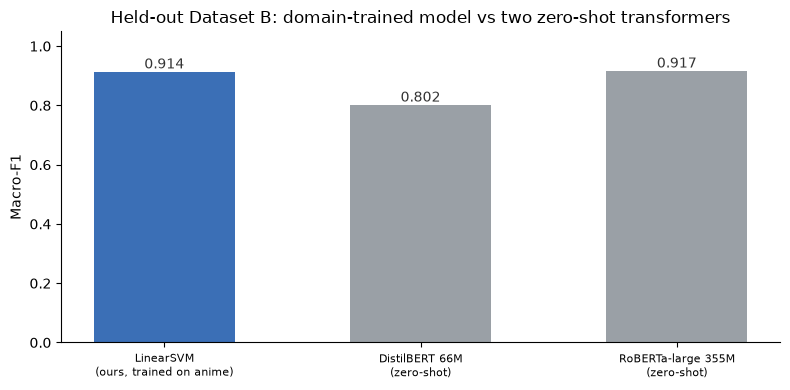

In [20]:

# Step 8e - second transformer benchmark: RoBERTa-large on Dataset B

# siebert/sentiment-roberta-large-english is RoBERTa-large (355M params) fine-tuned
# for BINARY sentiment. At ~600 ms/review it is run on Dataset B only (843 reviews),
# not the 3,205-row validation set, which would take about 32 minutes.
B_rob_pred = np.array([1 if l == "POSITIVE" else 0
                       for l in cached_sentiment(ROBERTA, _B_text, batch_size=8)])

print("\nRoBERTa-large (zero-shot) on Dataset B:")
print(classification_report(yB, B_rob_pred, target_names=["Negative (0)", "Positive (1)"]))

# three-way comparison on the held-out set
three_way = pd.DataFrame({
    f"{best_name} (ours, trained on anime)": _scores(yB, B_pred),
    "DistilBERT 66M (zero-shot)":            _scores(yB, B_bert_pred),
    "RoBERTa-large 355M (zero-shot)":        _scores(yB, B_rob_pred),
})
print("\n=== THREE-WAY COMPARISON ON HELD-OUT DATASET B ===")
display(three_way)

# visualise macro-F1, the metric we rank on
fig, ax = plt.subplots(figsize=(8, 4))
names  = list(three_way.columns)
scores = [three_way[c]["Macro-F1"] for c in names]
bars = ax.bar(range(len(names)), scores,
              color=["#3B6FB6", "#9AA0A6", "#9AA0A6"], width=0.55)
for b, s in zip(bars, scores):
    ax.annotate(f"{s:.3f}", (b.get_x() + b.get_width()/2, s),
                ha="center", va="bottom", fontsize=10, color="#333")
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace(" (", "\n(") for n in names], fontsize=8)
ax.set_ylabel("Macro-F1"); ax.set_ylim(0, 1.05)
ax.set_title("Held-out Dataset B: domain-trained model vs two zero-shot transformers")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()


### Insight — the large transformer matches us, and that matters

| | Linear SVM (ours) | DistilBERT | RoBERTa-large |
|---|---|---|---|
| Accuracy | **0.9442** | 0.8446 | 0.9431 |
| Macro-F1 | 0.9136 | 0.8017 | **0.9166** |
| F1 (negative) | 0.8622 | 0.7095 | **0.8696** |

- **RoBERTa edges us on macro-F1 by 0.003, zero-shot**, so "domain beats size" would have been too convenient
  a conclusion. Model quality matters.
- **But it is not free:** ~600 ms per review against ~23 ms for our full pipeline, cleaning included (measured
  with `predict.py` on the same 843 reviews) — about **25× slower** — plus a 1.4 GB model that cannot be
  retrained without a GPU.
- **Its whole advantage is on the negative class** (recall 0.97), because it never learned our 4 : 1 positive
  prior. That independently confirms the negative class is where the headroom is.
- A transformer **fine-tuned** on this data would likely beat both; it was ruled out on cost, not merit.

## 10. Save the final model & business interpretation

In [21]:

# Step 9 — persist the trained model for the demo

MODEL_PATH = os.path.join(DATA_DIR, "final_sentiment_model.joblib")
joblib.dump(final_model, MODEL_PATH)
print(f"Saved final model -> {MODEL_PATH}")

# sanity check: reload and predict two hand-written reviews
reloaded = joblib.load(MODEL_PATH)
demo = pd.DataFrame({
    "clean_text": ["masterpiece stunning animation brilliant story highly recommend",
                   "boring waste time generic bad pacing disappointing"],
    "exclamation_count": [2, 0], "question_count": [0, 1], "uppercase_word_count": [1, 0],
})
print("Demo predictions (1=pos, 0=neg):", reloaded.predict(demo).tolist())


Saved final model -> data\final_sentiment_model.joblib
Demo predictions (1=pos, 0=neg): [1, 0]


### Recommendation: deploy the Linear SVM

On unseen reviews it reaches **94.4% accuracy and 0.914 macro-F1**, and it works on new titles because it
relies on sentiment words, not names.

| | Linear SVM | RoBERTa-large |
|---|---|---|
| Accuracy / macro-F1 | 0.9442 / 0.9136 | 0.9431 / 0.9166 |
| Time per review | ~23 ms, cleaning included | ~600 ms |
| Model size | under 1 MB | ~1.4 GB |
| Retrainable on a CPU / explainable | Yes / Yes | No / No |

For a system that scores a whole catalogue continuously and has to justify its flags to people, the same
accuracy at ~25× the speed, with explainable output, is worth 0.003 of macro-F1.

**Weak spot:** negative-class F1 is 0.86 against 0.96 for positive, because there is less negative data to
learn from. Operational rule: **negative predictions with low confidence should be checked by a human**
(tested in Section 12).

**Next steps:** (1) scrape more negative reviews by targeting low-rated titles — the highest-value fix, since
the negative class is exactly where RoBERTa's advantage lies; (2) fine-tune RoBERTa on this corpus, which
needs a GPU.

## 11. Challenges and lessons

| Challenge | What it changed |
|---|---|
| 4 : 1 class imbalance | Handled four ways — dropping the neutral band, stratified splits, class weights, ranking by macro-F1 — and still the model's main weakness |
| Removing character names | The first rule (≤ 2 shows) caught almost nothing, because sequels count as separate titles. Found only by checking the step's *output* |
| A plausible metric giving wrong answers | The "most distinctive words" ranking filled with names until a minimum-shows guard was added |
| How far to trust an external word list | Using the lexicon to *protect* words was tested and rejected, because it rescued title words. It verifies the threshold instead |
| Runtime | Ruled out fine-tuning; RoBERTa runs on Dataset B only |

**Lessons**
- **Check outputs; don't assume the code did what was intended.** Several problems above only showed up in the printed results.
- **Preparation beats tuning.** Grid search changed nothing; cleaning and name removal drove the performance.
- **The best model isn't always the most sophisticated one.** Cost, speed and explainability count alongside the score.
- **Keep decisions traceable.** Raw data stays raw, and freezing the cleaning artifacts is what let Dataset B be cleaned identically.

## 12. Business scenario — the platform health dashboard

**Scenario.** Sarah is a content manager at a streaming platform. A newly licensed title starts collecting
reviews — text only, no ratings yet — and she needs to know within a day whether audiences like it, without
reading them.

| Indicator | Definition |
|---|---|
| **Catalogue Sentiment Score** | % of reviews classified positive |
| **Underperforming Content Alert** | Raised when negative sentiment exceeds **30%** |

Three titles from Dataset B are scored with their star ratings **withheld**; the real ratings are revealed
afterwards as a check.

In [22]:

# Step 10 - business scenario: the two platform-health indicators

DEMO_TITLES = ["Clannad: After Story", "Dandadan", "Sword Art Online"]
ALERT_THRESHOLD = 0.30      # flag a title when negative sentiment passes 30%

rows, per_review = [], {}
for title in DEMO_TITLES:
    sub = dfB[dfB["anime_title"] == title]
    if sub.empty:
        continue
    Xs     = sub[["clean_text"] + META_COLS]
    pred   = final_model.predict(Xs)
    margin = final_model.decision_function(Xs)      # signed distance from the boundary
    neg_rate = float((pred == 0).mean())

    per_review[title] = pd.DataFrame({
        "predicted":  np.where(pred == 1, "positive", "negative"),
        "confidence": np.abs(margin).round(2),
        "review": [" ".join(str(t).split())[:90] + "..." for t in sub["review_text"]],
    })

    rows.append({
        "Title": title,
        "Reviews": len(sub),
        "Sentiment Score %": round(float((pred == 1).mean()) * 100, 1),
        "Negative %": round(neg_rate * 100, 1),
        "Status": "*** ALERT: underperforming ***" if neg_rate > ALERT_THRESHOLD else "healthy",
    })

dashboard = pd.DataFrame(rows).sort_values("Sentiment Score %", ascending=False)
print("=" * 78)
print("PLATFORM HEALTH DASHBOARD".center(78))
print(f"(alert threshold: negative sentiment above {ALERT_THRESHOLD:.0%})".center(78))
print("=" * 78)
display(dashboard)

flagged = dashboard[dashboard["Status"].str.contains("ALERT")]
print(f"\nTitles requiring attention today: {len(flagged)} of {len(dashboard)}")
for _, r in flagged.iterrows():
    print(f"  - {r['Title']}: {r['Negative %']}% negative across {r['Reviews']} reviews")


                          PLATFORM HEALTH DASHBOARD                           
               (alert threshold: negative sentiment above 30%)                


,Title,Reviews,Sentiment Score %,Negative %,Status
0,Clannad: After Story,9,88.9,11.1,healthy
1,Dandadan,12,58.3,41.7,*** ALERT: underperforming ***
2,Sword Art Online,7,14.3,85.7,*** ALERT: underperforming ***



Titles requiring attention today: 2 of 3
  - Dandadan: 41.7% negative across 12 reviews
  - Sword Art Online: 85.7% negative across 7 reviews


In [23]:

# Step 10b - drill down into the flagged title, as Sarah would

if not flagged.empty:
    worst = flagged.iloc[0]["Title"]
    print(f"DRILL-DOWN: {worst}\n" + "-" * 78)
    display(per_review[worst].sort_values("confidence", ascending=False))

    # the low-confidence negatives are the ones our recommendation says a human checks
    low_conf = per_review[worst].query("predicted == 'negative' and confidence < 0.5")
    print(f"Negative predictions with confidence < 0.5 (flagged for human review): "
          f"{len(low_conf)} of {(per_review[worst]['predicted'] == 'negative').sum()}")


DRILL-DOWN: Dandadan
------------------------------------------------------------------------------


,predicted,confidence,review
0,negative,2.31,Dandadan - A Misguided Attempt at Entertainmen...
6,positive,1.89,"Going into Dandadan, I honestly had ZERO expec..."
11,positive,1.86,Dandadan has made me fall in love with anime o...
3,positive,1.86,Out of all the anime that was set to air this ...
8,positive,1.81,I waited a whole year for this anime to releas...
4,positive,1.60,"This is one of those ""watch and feel good"" ani..."
10,positive,1.43,"Well, the first season of one of my favorite a..."
2,negative,1.19,This must be one of the worst animes I've seen...
1,negative,0.90,I would not allow this anime to take up space ...
7,positive,0.73,OH MY BALLS THES ANIME IS SO GOOD YOU H A V E ...


Negative predictions with confidence < 0.5 (flagged for human review): 2 of 5


VALIDATION - predictions against the withheld star ratings


,Title,Predicted positive %,Actual positive %,Mean star rating,Correct,of,Gap (pp)
0,Clannad: After Story,88.9,100.0,9.6,8,9,-11.1
1,Dandadan,58.3,75.0,7.3,10,12,-16.7
2,Sword Art Online,14.3,14.3,4.1,7,7,0.0


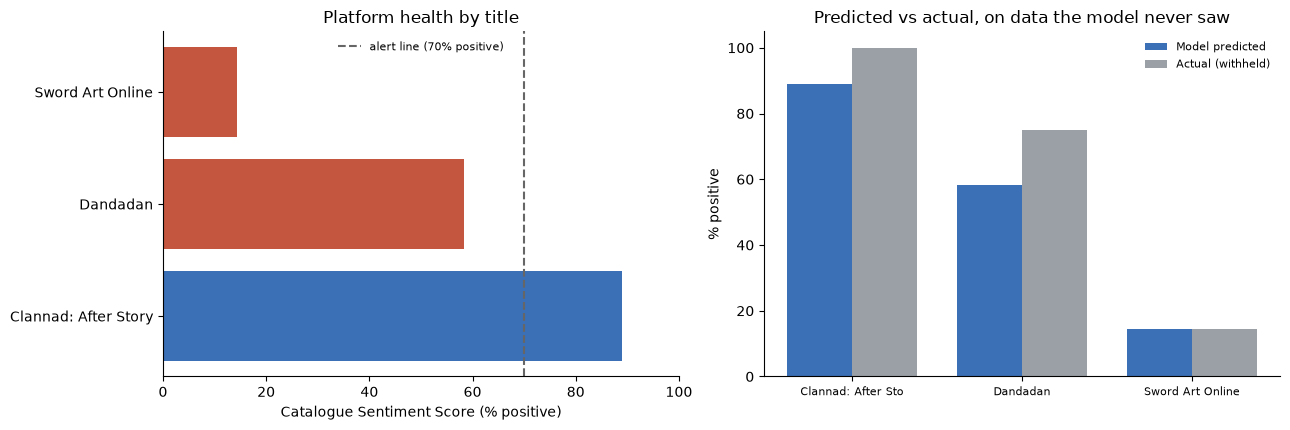

In [24]:

# Step 10c - validation: reveal the real ratings the model never saw

check = []
for title in DEMO_TITLES:
    sub = dfB[dfB["anime_title"] == title]
    if sub.empty:
        continue
    Xs = sub[["clean_text"] + META_COLS]
    pred = final_model.predict(Xs)
    check.append({
        "Title": title,
        "Predicted positive %": round(float((pred == 1).mean()) * 100, 1),
        "Actual positive %":    round(float((sub["sentiment"] == 1).mean()) * 100, 1),
        "Mean star rating":     round(float(sub["rating"].mean()), 1),
        "Correct": int((pred == sub["sentiment"].values).sum()),
        "of": len(sub),
    })
validation = pd.DataFrame(check)
validation["Gap (pp)"] = (validation["Predicted positive %"]
                          - validation["Actual positive %"]).round(1)
print("VALIDATION - predictions against the withheld star ratings")
display(validation)

# ---- visual: the dashboard Sarah sees, and how close it was --------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

d = dashboard.set_index("Title")
colors = ["#C4553E" if "ALERT" in s else "#3B6FB6" for s in d["Status"]]
axes[0].barh(d.index, d["Sentiment Score %"], color=colors)
axes[0].axvline(100 - ALERT_THRESHOLD * 100, ls="--", color="#666",
                label=f"alert line ({100-ALERT_THRESHOLD*100:.0f}% positive)")
axes[0].set_xlim(0, 100); axes[0].set_xlabel("Catalogue Sentiment Score (% positive)")
axes[0].set_title("Platform health by title")
axes[0].legend(frameon=False, fontsize=8)
axes[0].spines[["top", "right"]].set_visible(False)

x = np.arange(len(validation)); w = 0.38
axes[1].bar(x - w/2, validation["Predicted positive %"], w, label="Model predicted",
            color="#3B6FB6")
axes[1].bar(x + w/2, validation["Actual positive %"], w, label="Actual (withheld)",
            color="#9AA0A6")
axes[1].set_xticks(x)
axes[1].set_xticklabels([t[:18] for t in validation["Title"]], fontsize=8)
axes[1].set_ylabel("% positive"); axes[1].set_ylim(0, 105)
axes[1].set_title("Predicted vs actual, on data the model never saw")
axes[1].legend(frameon=False, fontsize=8)
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout(); plt.show()


### Insight — the alert works, and so does the safeguard

| Title | Predicted positive | Actual positive | Verdict |
|---|---|---|---|
| Clannad: After Story | 88.9% | 100% | Healthy — correct |
| Dandadan | 58.3% | 75.0% | **Flagged — false alarm** |
| Sword Art Online | 14.3% | 14.3% | Flagged — correct, all 7 reviews right |

**The low-confidence rule resolves the false alarm.** For *Dandadan*, the three confident negative
predictions were all correct, and the two low-confidence ones (< 0.5) were both wrong: slang like *"the reason
why I fw this anime so bad"*, and *"so beautiful to see my beloved weird manga"*. If Sarah checks those two by
hand, *Dandadan* drops from 41.7% to 25% negative — below the 30% threshold — and the alert clears itself.

*Limitations:* only 7–12 reviews per title here, so each error moves a percentage by 8–14 points. The 30%
threshold is a business choice; the precision-recall curve in Section 7 is how you would set it deliberately.

## 13. Aspect analysis — *what* are reviewers complaining about?

The dashboard says *how many* reviews are negative, not *why*. The business question is which elements —
pacing, adaptation, story, animation — drive satisfaction and complaints.

**Attempt 1, abandoned: read the model's bigram weights.** Phrases contradicted their own meaning (*art good*
−0.76, *great pace* −0.34). With 20,000 correlated features, individual coefficients are not stable
estimates (*multicollinearity*), even though the model as a whole is accurate.

**Attempt 2, used: sentence-level lexicon scoring.** Reviews are split into sentences, and for each sentence
mentioning an aspect, positive and negative words from the Hu & Liu lexicon are counted. Working per sentence
means *"gorgeous animation, but the story was a mess"* credits the praise to animation and the criticism to
story. *Limitation:* it links sentiment by sentence, not by grammar, so it is an approximation rather than full
aspect-based sentiment analysis.

In [25]:

# Step 11 - aspect sentiment via sentence-level lexicon scoping

import nltk
nltk.download("opinion_lexicon", quiet=True)
from nltk.corpus import opinion_lexicon

POS_WORDS = set(opinion_lexicon.positive())
NEG_WORDS = set(opinion_lexicon.negative()) | {
    "rushed", "bland", "generic", "soulless", "unfunny", "overrated", "mediocre", "boring"}

ASPECT_TERMS = {
    "Story / writing": {"story", "stories", "plot", "writing", "narrative", "premise",
                        "twist", "ending", "plotline"},
    "Animation / art": {"animation", "animations", "art", "artwork", "visual", "visuals",
                        "cgi", "artstyle", "animated"},
    "Characters":      {"character", "characters", "cast", "protagonist", "villain",
                        "characterisation", "characterization"},
    "Pacing":          {"pacing", "pace", "rushed", "filler", "fillers", "slow", "dragged"},
    "Music / sound":   {"music", "ost", "soundtrack", "soundtracks", "voice", "sound",
                        "dub", "dubbed", "seiyuu"},
    "Adaptation":      {"adaptation", "adaptations", "adapted", "manga", "source"},
}

SENT_SPLIT = re.compile(r"[.!?]+")
WORD_RE    = re.compile(r"[a-z']+")

stats    = {a: {"sentences": 0, "pos": 0, "neg": 0} for a in ASPECT_TERMS}
critical = {a: [] for a in ASPECT_TERMS}     # example sentences that criticise the aspect

for text in df["review_text"].dropna().astype(str):
    for sentence in SENT_SPLIT.split(text.lower()):
        toks = set(WORD_RE.findall(sentence))
        if not toks:
            continue
        n_pos, n_neg = len(toks & POS_WORDS), len(toks & NEG_WORDS)
        if n_pos == 0 and n_neg == 0:
            continue                          # no sentiment expressed in this sentence
        for aspect, terms in ASPECT_TERMS.items():
            if toks & terms:
                stats[aspect]["sentences"] += 1
                stats[aspect]["pos"] += n_pos
                stats[aspect]["neg"] += n_neg
                if n_neg > n_pos and len(critical[aspect]) < 3 and 40 < len(sentence) < 190:
                    critical[aspect].append(sentence.strip())

rows = []
for a, s in stats.items():
    total = s["pos"] + s["neg"]
    rows.append({
        "Aspect": a,
        "Sentences discussing it": s["sentences"],
        "Positive words": s["pos"],
        "Negative words": s["neg"],
        "% negative": round(s["neg"] / total * 100, 1) if total else None,
    })
aspect_tbl = pd.DataFrame(rows).sort_values("% negative", ascending=False)

print("ASPECT SENTIMENT - sentence-level, Hu & Liu lexicon")
print("higher % negative = reviewers criticise this aspect more when they raise it\n")
display(aspect_tbl)


ASPECT SENTIMENT - sentence-level, Hu & Liu lexicon
higher % negative = reviewers criticise this aspect more when they raise it



,Aspect,Sentences discussing it,Positive words,Negative words,% negative
3,Pacing,7188,8673,10757,55.4
0,Story / writing,49212,65615,58604,47.2
2,Characters,61794,89189,59845,40.2
5,Adaptation,6915,9899,5841,37.1
1,Animation / art,23540,40398,15355,27.5
4,Music / sound,20385,33976,11484,25.3


In [26]:

# Step 11b - what the criticism actually sounds like

# Selecting example sentences needs more care than the aggregate counts. Two filters
# are applied so the examples are genuine criticism of the work:
#   1. the sentence must contain an explicit EVALUATION word ("issues", "poor", "bland"),
#      which excludes plot description that merely uses dark vocabulary
#   2. that evaluation word must not be negated ("not bad", "no problems")
CRITICISM = {"issue", "issues", "problem", "problems", "bad", "poor", "poorly", "weak",
             "boring", "bored", "dull", "lazy", "rushed", "mess", "messy", "worst",
             "terrible", "awful", "disappointing", "disappointed", "flaw", "flaws",
             "flawed", "mediocre", "bland", "generic", "waste", "ruined", "ruin",
             "drags", "dragged", "draggy", "confusing", "nonsensical", "wasted"}
NEGATORS = {"not", "no", "n't", "never", "nothing", "without", "hardly", "barely", "isn"}
NEGATED_PHRASES = ("not bad", "no problem", "not the case", "nothing wrong", "not saying",
                   "not only", "far from bad")

def is_genuine_criticism(tokens, sentence):
    """Sentence contains at least one un-negated evaluation word."""
    if any(p in sentence for p in NEGATED_PHRASES):
        return False
    marks = [i for i, t in enumerate(tokens) if t in CRITICISM]
    if not marks:
        return False
    return any(not (set(tokens[max(0, i-4):i]) & NEGATORS) for i in marks)

examples = {a: [] for a in ASPECT_TERMS}
for text in df["review_text"].dropna().astype(str):
    for sentence in SENT_SPLIT.split(text.lower()):
        toks = WORD_RE.findall(sentence)
        tset = set(toks)
        if not tset or not is_genuine_criticism(toks, sentence):
            continue
        if len(tset & NEG_WORDS) <= len(tset & POS_WORDS):
            continue                                  # must be net negative
        for aspect, terms in ASPECT_TERMS.items():
            if (tset & terms) and len(examples[aspect]) < 3 and 45 < len(sentence) < 185:
                examples[aspect].append(sentence.strip())

pct = aspect_tbl.set_index("Aspect")["% negative"]
for aspect in aspect_tbl["Aspect"]:
    if examples[aspect]:
        print(f"\n{aspect}  ({pct[aspect]}% negative)")
        for s in examples[aspect]:
            print(f'   "{s}"')



Pacing  (55.4% negative)
   "there are some other problems, such as pacing issues where the series just grinds to a screeching halt and drags on for a fair bit"
   "6 i'm sorry, i really am, but there are fundamental structure and pacing issues with aot"
   "[end spoiler] there are also general pacing issues: it feels slow, yet we aren't given time to get to know the characters so when the inevitably die, it's hard to really care"

Story / writing  (47.2% negative)
   "the story breaks the mold of generic revenge story and adds things like conspiracy and thriller aspects that propels the experience"
   "the story literally goes no where, the characters become stale and boring, and the main character, who was a thorough badass, actually regresses into an indecisive child"
   "anyways, here's my problem with the story pacing"

Characters  (40.2% negative)
   "this is a huge problem in a series where death and survival are the main aspects, and a character’s death has no impact unless th

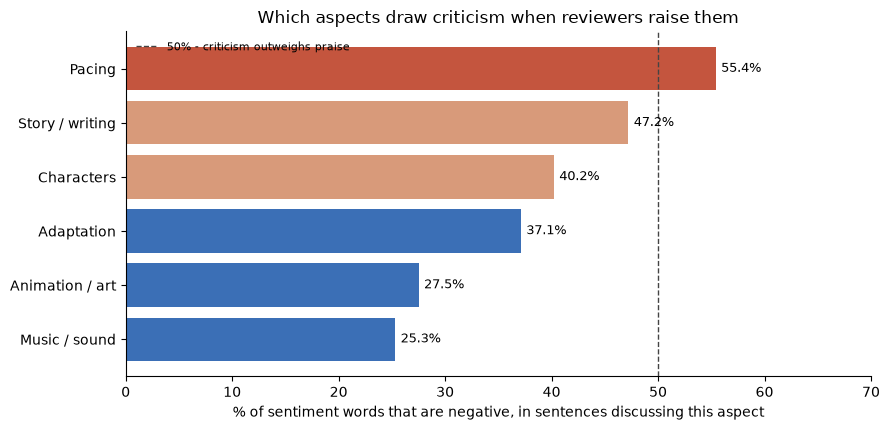

In [27]:

# Step 11c - the chart Sarah would read

fig, ax = plt.subplots(figsize=(9, 4.4))
d = aspect_tbl.set_index("Aspect")["% negative"]
colors = ["#C4553E" if v >= 50 else ("#D89A7A" if v >= 40 else "#3B6FB6") for v in d]
ax.barh(d.index[::-1], d.values[::-1], color=colors[::-1])
ax.axvline(50, ls="--", color="#444", lw=1, label="50% - criticism outweighs praise")
ax.set_xlabel("% of sentiment words that are negative, in sentences discussing this aspect")
ax.set_xlim(0, 70)
ax.set_title("Which aspects draw criticism when reviewers raise them")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
for y, v in enumerate(d.values[::-1]):
    ax.annotate(f"{v}%", (v, y), va="center", xytext=(4, 0),
                textcoords="offset points", fontsize=9)
plt.tight_layout(); plt.show()


### Insight — pacing is the complaint; animation and music are the praise

| Aspect | Sentences | % negative |
|---|---|---|
| **Pacing** | 7,188 | **55.4%** — the only aspect where criticism outweighs praise |
| Story / writing | 49,212 | 47.2% — divides audiences |
| Characters | 61,794 | 40.2% |
| Adaptation | 6,915 | 37.1% |
| Animation / art | 23,540 | 27.5% |
| Music / sound | 20,385 | **25.3%** — the least criticised |

**Business takeaway:** when evaluating a licence, check the episode count against the source material — a
rushed adaptation is the most likely cause of negative sentiment. Production values (animation, music) are
rarely the problem.

*Limitations:* plot summaries use dark vocabulary (*"a titan rips…"*) that inflates the story and character
figures, which if anything widens pacing's lead; negation is only handled approximately.

### 13b. Per-title breakdown

Each dashboard title's aspect scores are compared with the catalogue average, because what matters is
whether a title draws **more** criticism than usual. This uses every review held for the title (Dataset A +
B), not just B: it is a text analysis that never trains or predicts with the model, so the held-out rule does
not apply, and 7–12 reviews would be too few. Aspects with fewer than 10 sentences are suppressed.

In [28]:

# Step 11d - per-title aspect breakdown vs the catalogue baseline

def scan_aspects(texts):
    """Same sentence-level lexicon scan as Step 11, applied to any set of reviews."""
    st = {a: {"sentences": 0, "pos": 0, "neg": 0} for a in ASPECT_TERMS}
    for text in texts:
        for sentence in SENT_SPLIT.split(str(text).lower()):
            toks = set(WORD_RE.findall(sentence))
            if not toks:
                continue
            p, n = len(toks & POS_WORDS), len(toks & NEG_WORDS)
            if p == 0 and n == 0:
                continue
            for aspect, terms in ASPECT_TERMS.items():
                if toks & terms:
                    st[aspect]["sentences"] += 1
                    st[aspect]["pos"] += p
                    st[aspect]["neg"] += n
    return st

MIN_SENTENCES = 10          # below this the percentage is too noisy to report

# every review we hold for a title, from both Dataset A and Dataset B
all_reviews = pd.concat([df[["anime_title", "review_text"]],
                         dfB[["anime_title", "review_text"]]], ignore_index=True)
baseline = aspect_tbl.set_index("Aspect")["% negative"]

per_title = {}
for title in DEMO_TITLES:
    sub = all_reviews[all_reviews["anime_title"] == title]
    if sub.empty:                     # title absent, e.g. after a reduced scrape
        continue
    st  = scan_aspects(sub["review_text"].dropna())
    rows, dropped = [], []
    for aspect, s in st.items():
        total = s["pos"] + s["neg"]
        if s["sentences"] < MIN_SENTENCES or total == 0:
            dropped.append(f"{aspect} ({s['sentences']})")
            continue
        pct = s["neg"] / total * 100
        rows.append({"Aspect": aspect,
                     "Sentences": s["sentences"],
                     "% negative": round(pct, 1),
                     "Catalogue avg": baseline[aspect],
                     "Difference": round(pct - baseline[aspect], 1)})
    per_title[title] = (len(sub), pd.DataFrame(rows).sort_values("Difference", ascending=False),
                        dropped)

status = dashboard.set_index("Title")["Status"]
for title, (n_rev, tbl, dropped) in per_title.items():
    print("=" * 78)
    print(f"{title}   |   {n_rev} reviews held   |   dashboard: {status.get(title, 'not in Dataset B')}")
    print("=" * 78)
    display(tbl)
    if dropped:
        print(f"   suppressed, under {MIN_SENTENCES} sentences: {', '.join(dropped)}")
    print()


Clannad: After Story   |   93 reviews held   |   dashboard: healthy


,Aspect,Sentences,% negative,Catalogue avg,Difference
5,Adaptation,15,41.7,37.1,4.6
1,Animation / art,161,24.5,27.5,-3.0
4,Music / sound,169,21.1,25.3,-4.2
2,Characters,417,33.8,40.2,-6.4
0,Story / writing,687,37.6,47.2,-9.6
3,Pacing,32,39.2,55.4,-16.2



Dandadan   |   85 reviews held   |   dashboard: *** ALERT: underperforming ***


,Aspect,Sentences,% negative,Catalogue avg,Difference
1,Animation / art,112,32.2,27.5,4.7
0,Story / writing,183,50.4,47.2,3.2
2,Characters,158,43.1,40.2,2.9
3,Pacing,23,55.3,55.4,-0.1
4,Music / sound,43,23.7,25.3,-1.6
5,Adaptation,40,34.7,37.1,-2.4



Sword Art Online   |   80 reviews held   |   dashboard: *** ALERT: underperforming ***


,Aspect,Sentences,% negative,Catalogue avg,Difference
1,Animation / art,218,36.9,27.5,9.4
2,Characters,541,49.4,40.2,9.2
0,Story / writing,439,55.0,47.2,7.8
3,Pacing,95,61.4,55.4,6.0
4,Music / sound,138,24.5,25.3,-0.8
5,Adaptation,13,29.6,37.1,-7.5


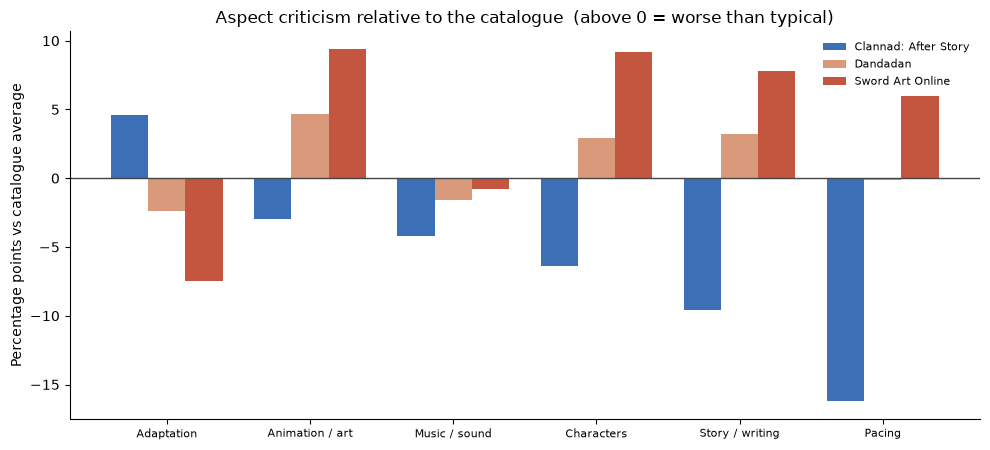

In [29]:
# ============================================================
# Step 11e - the same comparison as one chart
# ============================================================
frames = []
for title, (_, tbl, _) in per_title.items():
    t = tbl.set_index("Aspect")["Difference"].rename(title)
    frames.append(t)
diff = pd.concat(frames, axis=1)

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(diff.index)); w = 0.26
palette = ["#3B6FB6", "#D89A7A", "#C4553E"]
for i, col in enumerate(diff.columns):
    ax.bar(x + (i - 1) * w, diff[col].values, w, label=col[:22], color=palette[i % 3])
ax.axhline(0, color="#444", lw=1)
ax.set_xticks(x); ax.set_xticklabels(diff.index, fontsize=8)
ax.set_ylabel("Percentage points vs catalogue average")
ax.set_title("Aspect criticism relative to the catalogue  (above 0 = worse than typical)")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()


### Insight — the aspect profile is an independent second opinion

| Aspect (points vs catalogue) | Clannad *(healthy)* | Dandadan *(flagged)* | Sword Art Online *(flagged)* |
|---|---|---|---|
| Animation / art | −3.0 | +4.7 | **+9.4** |
| Characters | −6.4 | +2.9 | **+9.2** |
| Story / writing | −9.6 | +3.2 | **+7.8** |
| Pacing | **−16.2** | −0.1 | **+6.0** |
| Music / sound | −4.2 | −1.6 | −0.8 |
| Adaptation | +4.6 | −2.4 | −7.5 |

- **Sword Art Online** is worse than typical on four aspects — a broad, real problem, matching its correct alert.
- **Clannad** is better than typical almost everywhere, most of all on pacing.
- **Dandadan** sits within ~5 points of average on everything — no real problem, which agrees that its alert
  was a false alarm.

The aspect analysis never uses the classifier, so two independent methods agreeing on *Sword Art Online* and
disagreeing on *Dandadan* is stronger evidence than either alone. **Rule of thumb:** flagged *and* an aspect
clearly above average → investigate that aspect; flagged but every aspect near average → apply the
low-confidence check before escalating.

*Reliability:* Adaptation rests on only 13–40 sentences per title, so treat that row as indicative.